# 05 — Model Evaluation

## Objective

The objective of this notebook is to evaluate the performance of the trained Linear Regression model using an independent test dataset.

The evaluation focuses on measuring prediction errors, comparing the trained model against a baseline model, and analyzing prediction quality through visualizations and residual analysis.

## Steps

1. Import the required libraries.
2. Load the saved test dataset.
3. Inspect and validate the test dataset.
4. Load the best trained model.
5. Separate the test features (X_test) and target variable (y_test).
6. Generate predictions using the trained model.
7. Calculate evaluation metrics (MAE, MSE, RMSE, and R²).
8. Build a DummyRegressor baseline model.
9. Compare Linear Regression performance against the baseline.
10. Analyze actual versus predicted prices.
11. Investigate the largest prediction errors.
12. Perform residual analysis.
13. Visualize prediction performance and residual distributions.

## Expected Outcome

Assess how well the trained model generalizes to unseen data, determine whether it performs better than a simple baseline, and identify possible areas for future improvement.

In [17]:
### 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.dummy import DummyRegressor

In [2]:
### 2. Load the Test Dataset
test_data = pd.read_csv(
    "../data/processed/test_data.csv"
)
### 3. Inspect and Validate Test Data
test_data.head()

,Make,Model,Year,Engine Size,Mileage,Fuel Type,Transmission,Price
0,Audi,Model B,2011,2.7,146367,Petrol,Manual,21963.662463
1,Honda,Model C,2001,3.6,55547,Petrol,Manual,17639.820917
2,BMW,Model E,2003,1.5,136878,Electric,Automatic,14717.798535
3,BMW,Model E,2018,1.1,105153,Diesel,Manual,21271.276378
4,Honda,Model B,2010,1.1,194151,Electric,Manual,18596.853815


In [3]:
test_data.shape

(200, 8)

In [4]:
test_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Make          200 non-null    str    
 1   Model         200 non-null    str    
 2   Year          200 non-null    int64  
 3   Engine Size   200 non-null    float64
 4   Mileage       200 non-null    int64  
 5   Fuel Type     200 non-null    str    
 6   Transmission  200 non-null    str    
 7   Price         200 non-null    float64
dtypes: float64(2), int64(2), str(4)
memory usage: 17.6 KB


In [5]:
test_data.isnull().sum()

Make            0
Model           0
Year            0
Engine Size     0
Mileage         0
Fuel Type       0
Transmission    0
Price           0
dtype: int64

In [6]:
### 4. Load the Best Trained Model
model = joblib.load(
    "../models/linear_regression.pkl"
)

In [7]:
### 5. Prepare Test Features and Target
X_test = test_data.drop(columns=["Price"])
y_test = test_data["Price"]

In [8]:
### 6. Generate Predictions
y_pred = model.predict(X_test)

In [9]:
results = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": y_pred
})

results.head(10)

,Actual Price,Predicted Price
0,21963.662463,22575.233118
1,17639.820917,23594.885453
2,14717.798535,16925.362544
3,21271.276378,25302.502661
4,18596.853815,16624.892044
5,19071.482402,24846.958621
6,34637.417286,32019.035102
7,18646.114488,20706.914170
8,22913.228253,24270.657408
9,21309.027466,19461.111371


In [10]:
### 7. Evaluate Model Performance
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 1751.8345325745538
MSE: 4684620.291091441
RMSE: 2164.3983670044295
R2 Score: 0.841825425221463


In [11]:
results["Error"] = (
    results["Actual Price"] -
    results["Predicted Price"]
)

results["Absolute Error"] = results["Error"].abs()

results.head(10)

,Actual Price,Predicted Price,Error,Absolute Error
0,21963.662463,22575.233118,-611.570655,611.570655
1,17639.820917,23594.885453,-5955.064536,5955.064536
2,14717.798535,16925.362544,-2207.564010,2207.564010
3,21271.276378,25302.502661,-4031.226283,4031.226283
4,18596.853815,16624.892044,1971.961771,1971.961771
5,19071.482402,24846.958621,-5775.476219,5775.476219
6,34637.417286,32019.035102,2618.382184,2618.382184
7,18646.114488,20706.914170,-2060.799682,2060.799682
8,22913.228253,24270.657408,-1357.429155,1357.429155
9,21309.027466,19461.111371,1847.916094,1847.916094


In [12]:
results.sort_values(
    by="Absolute Error",
    ascending=False
).head(10)

,Actual Price,Predicted Price,Error,Absolute Error
47,33028.546022,26908.138380,6120.407643,6120.407643
1,17639.820917,23594.885453,-5955.064536,5955.064536
5,19071.482402,24846.958621,-5775.476219,5775.476219
84,19012.699961,24302.139315,-5289.439354,5289.439354
111,23986.216706,18716.757008,5269.459699,5269.459699
104,28398.167386,23182.198572,5215.968814,5215.968814
21,20813.969200,25309.684559,-4495.715358,4495.715358
34,19163.705108,23276.899451,-4113.194343,4113.194343
142,32167.280774,28100.248459,4067.032315,4067.032315
125,20466.600614,24530.648033,-4064.047419,4064.047419


In [13]:
### 8. Analyze Actual vs Predicted Prices
residuals = y_test - y_pred
print("Mean:", residuals.mean())
print("Median:", residuals.median())
print("Standard Deviation:", residuals.std())

Mean: -166.02364441185958
Median: -28.747633595712614
Standard Deviation: 2163.4367876734786


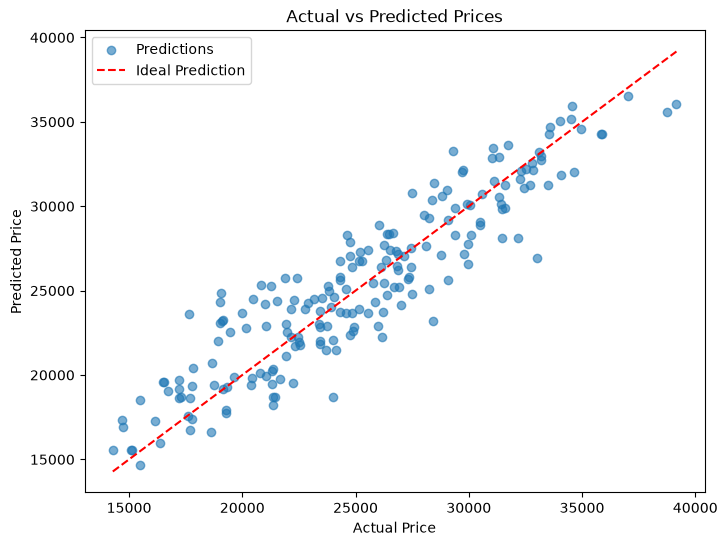

In [14]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6, label="Predictions")

# Ideal prediction line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--",
    label="Ideal Prediction"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Prices")

plt.legend()
plt.show()

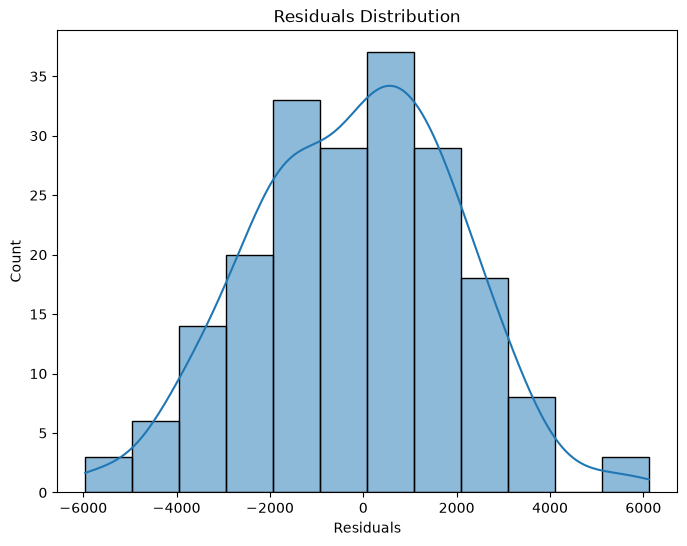

In [15]:
plt.figure(figsize=(8, 6))

sns.histplot(residuals, kde=True)

plt.xlabel("Residuals")
plt.title("Residuals Distribution")

plt.show()

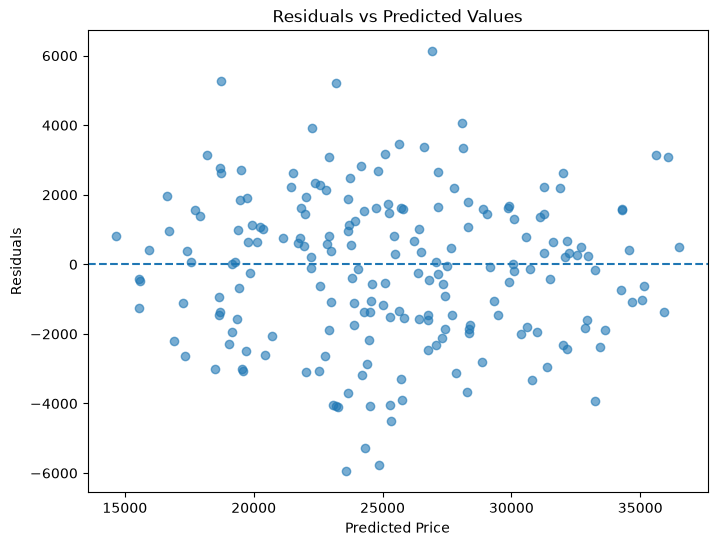

In [16]:
plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.6)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")

plt.show()

In [20]:
### 9. Load the Train Dataset
train_data = pd.read_csv("../data/processed/train_data.csv")
train_data.shape

(797, 8)

In [21]:
train_data.head()

,Make,Model,Year,Engine Size,Mileage,Fuel Type,Transmission,Price
0,BMW,Model B,2021,1.8,120035,Petrol,Automatic,27273.812400
1,Audi,Model C,2003,3.0,41722,Petrol,Manual,25038.939760
2,BMW,Model D,2011,1.1,75720,Petrol,Automatic,19873.074835
3,Toyota,Model E,2007,1.0,7394,Petrol,Automatic,24997.210476
4,Audi,Model D,2001,1.5,179115,Petrol,Manual,14696.849306


In [22]:
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 797 entries, 0 to 796
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Make          797 non-null    str    
 1   Model         797 non-null    str    
 2   Year          797 non-null    int64  
 3   Engine Size   797 non-null    float64
 4   Mileage       797 non-null    int64  
 5   Fuel Type     797 non-null    str    
 6   Transmission  797 non-null    str    
 7   Price         797 non-null    float64
dtypes: float64(2), int64(2), str(4)
memory usage: 69.8 KB


In [23]:
X_train = train_data.drop(columns=["Price"])
y_train = train_data["Price"]

In [24]:
### 9. Build a Baseline Model
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train, y_train)

,"strategy strategy: {""mean"", ""median"", ""quantile"", ""constant""}, default=""mean""Strategy to use to generate predictions.* ""mean"": always predicts the mean of the training set* ""median"": always predicts the median of the training set* ""quantile"": always predicts a specified quantile of the training set, provided with the quantile parameter.* ""constant"": always predicts a constant value that is provided by the user.",'mean'
,"constant constant: int or float or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
,"quantile quantile: float in [0.0, 1.0], default=NoneThe quantile to predict using the ""quantile"" strategy. A quantile of0.5 corresponds to the median, while 0.0 to the minimum and 1.0 to themaximum.",None
Name,Type,Value
"constant_ constant_: ndarray of shape (1, n_outputs)Mean or median or quantile of the training targets or constant valuegiven by the user.","ndarray[float64](1, 1)",[[25101.18]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](7,)","['Make','Model','Year',...,'Mileage','Fuel Type','Transmission']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,7
n_outputs_ n_outputs_: intNumber of outputs.,int,1


In [25]:
dummy_pred = dummy_model.predict(X_test)

In [26]:
### 10. Compare Model Performance
dummy_mae = mean_absolute_error(y_test, dummy_pred)

dummy_mse = mean_squared_error(y_test, dummy_pred)

dummy_rmse = np.sqrt(dummy_mse)

dummy_r2 = r2_score(y_test, dummy_pred)

In [27]:
comparison = pd.DataFrame({
    "Model": ["DummyRegressor", "Linear Regression"],
    "MAE": [dummy_mae, mae],
    "MSE": [dummy_mse, mse],
    "RMSE": [dummy_rmse, rmse],
    "R2 Score": [dummy_r2, r2]
})

comparison

,Model,MAE,MSE,RMSE,R2 Score
0,DummyRegressor,4478.283737,2.962856e+07,5443.212593,-0.000398
1,Linear Regression,1751.834533,4.684620e+06,2164.398367,0.841825
